In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the cleaned SEDS dataset
df = pd.read_csv('df_seds_cleaned.csv')

# Load the SEDS category/description file
categories = pd.read_excel('SEDS_categories.xlsx')

df.head()

,State,Year,B1ACB,B1PRB,BDACB,BDCCB,BDEIB,BDFDB,BDRCB,CLACB,...,SORCB,TPOPP,WWCCB,WWEIB,WWICB,WWPRB,WYCCB,WYEGB,WYICB,WYPRB
0,AK,1960,0.0,0.0,0.0,0.0,0.0,0.0,0.0,86.0,...,0.0,229.0,34.0,0.0,1840.0,3681.0,0.0,0.0,0.0,0.0
1,AK,1961,0.0,0.0,0.0,0.0,0.0,0.0,0.0,42.0,...,0.0,238.0,35.0,0.0,2288.0,4145.0,0.0,0.0,0.0,0.0
2,AK,1962,0.0,0.0,0.0,0.0,0.0,0.0,0.0,43.0,...,0.0,246.0,32.0,0.0,2511.0,4246.0,0.0,0.0,0.0,0.0
3,AK,1963,0.0,0.0,0.0,0.0,0.0,0.0,0.0,36.0,...,0.0,256.0,31.0,0.0,2700.0,4383.0,0.0,0.0,0.0,0.0
4,AK,1964,0.0,0.0,0.0,0.0,0.0,0.0,0.0,33.0,...,0.0,263.0,32.0,0.0,2993.0,4728.0,0.0,0.0,0.0,0.0


In [2]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Number of states:", df['State'].nunique())
print("Number of years:", df['Year'].nunique())
print("Year range:", df['Year'].min(), "-", df['Year'].max())

Number of rows: 3315
Number of columns: 56
Number of states: 51
Number of years: 65
Year range: 1960 - 2024


In [3]:
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate State-Year observations:", df.duplicated(['State', 'Year']).sum())

Total missing values: 0
Duplicate State-Year observations: 0


In [4]:
# Identify the energy variables
energy_cols = df.columns[2:]

print("Number of energy variables:", len(energy_cols))
print(energy_cols.tolist())

Number of energy variables: 54
['B1ACB', 'B1PRB', 'BDACB', 'BDCCB', 'BDEIB', 'BDFDB', 'BDRCB', 'CLACB', 'CLCCB', 'CLEIB', 'CLICB', 'CLPRB', 'CLRCB', 'EMACB', 'EMCCB', 'EMFDB', 'EMICB', 'GECCB', 'GEEGB', 'GEICB', 'GEPRB', 'GERCB', 'HYCCB', 'HYEGB', 'HYICB', 'HYPRB', 'NGACB', 'NGCCB', 'NGEIB', 'NGICB', 'NGMPB', 'NGRCB', 'NUEGB', 'NUPRB', 'PAACB', 'PACCB', 'PAEIB', 'PAICB', 'PAPRB', 'PARCB', 'SOCCB', 'SOEGB', 'SOICB', 'SOPRB', 'SORCB', 'TPOPP', 'WWCCB', 'WWEIB', 'WWICB', 'WWPRB', 'WYCCB', 'WYEGB', 'WYICB', 'WYPRB']


In [5]:
# View the category/description information
categories.columns

Index(['Category 0', 'Category 1', 'Category 2', 'Category 3', 'MSN Code',
       'Description', 'Unit'],
      dtype='object')

In [6]:
# Create a smaller lookup table for the MSN variables
variable_info = categories[['MSN Code', 'Description', 'Unit']].copy()

variable_info.head()

,MSN Code,Description,Unit
0,PAPRB,Crude oil production (including lease condensate),Billion Btu
1,PAACB,All petroleum products consumed by the transpo...,Billion Btu
2,PACCB,All petroleum products consumed by the commerc...,Billion Btu
3,PAEIB,All petroleum products consumed by the electri...,Billion Btu
4,PAICB,All petroleum products consumed by the industr...,Billion Btu


In [7]:
summary_stats = df[energy_cols].describe().T

summary_stats

,count,mean,std,min,25%,50%,75%,max
B1ACB,3315.0,532.407541,1.110588e+04,0.0,0.0,0.0,0.0,426607.0
B1PRB,3315.0,416.246154,5.055927e+03,0.0,0.0,0.0,0.0,137029.0
BDACB,3315.0,917.412368,3.015018e+03,0.0,0.0,0.0,235.5,37012.0
BDCCB,3315.0,6.871493,9.084437e+01,0.0,0.0,0.0,0.0,2194.0
BDEIB,3315.0,2.733937,4.185228e+01,0.0,0.0,0.0,0.0,900.0
BDFDB,3315.0,918.911011,3.849279e+03,0.0,0.0,0.0,0.0,47215.0
BDRCB,3315.0,22.733032,2.597594e+02,0.0,0.0,0.0,0.0,4668.0
CLACB,3315.0,68.404223,4.589956e+02,0.0,0.0,0.0,0.0,14588.0
CLCCB,3315.0,2487.257014,6.031015e+03,0.0,2.0,324.0,2659.5,89986.0
CLEIB,3315.0,257368.809050,3.038563e+05,0.0,17378.5,158806.0,371439.5,1675488.0


In [8]:
# Calculate the percentage of observations equal to zero
zero_percentage = (
    df[energy_cols]
    .eq(0)
    .mean() * 100
).sort_values(ascending=False)

zero_percentage.head(10)

,0
B1ACB,99.245852
BDCCB,99.034691
BDRCB,99.034691
BDEIB,98.853695
B1PRB,97.767722
WYICB,97.526395
WYCCB,94.932127
GEEGB,93.333333
HYCCB,92.518854
GEICB,82.865762


In [9]:
# Add descriptions to the zero-value summary
zero_summary = (
    zero_percentage
    .rename('Zero_Percentage')
    .reset_index()
    .rename(columns={'index': 'MSN Code'})
)

zero_summary = zero_summary.merge(
    variable_info,
    on='MSN Code',
    how='left'
)

zero_summary.head(10)

,MSN Code,Zero_Percentage,Description,Unit
0,B1ACB,99.245852,Renewable diesel consumed by the transportatio...,Billion Btu
1,BDCCB,99.034691,Biodiesel consumed by the commercial sector,Billion Btu
2,BDRCB,99.034691,Biodiesel consumed by the residential sector,Billion Btu
3,BDEIB,98.853695,Biodiesel consumed by the electric power sector,Billion Btu
4,B1PRB,97.767722,Renewable diesel production,Billion Btu
5,WYICB,97.526395,Wind energy consumed by the industrial sector,Billion Btu
6,WYCCB,94.932127,Wind energy consumed by the commercial sector,Billion Btu
7,GEEGB,93.333333,Geothermal energy consumed for electricity gen...,Billion Btu
8,HYCCB,92.518854,Hydropower consumed by the commercial sector,Billion Btu
9,GEICB,82.865762,Geothermal energy consumed by the industrial s...,Billion Btu


In [10]:
# Count negative observations for each energy variable
negative_counts = (
    (df[energy_cols] < 0)
    .sum()
    .sort_values(ascending=False)
)

negative_counts[negative_counts > 0]

,0
HYPRB,26
HYEGB,26
NUPRB,7
NUEGB,7
WWEIB,2
WYICB,1
WYPRB,1
WYEGB,1


In [11]:
# Describe the negative-value summary
negative_summary = (
    negative_counts[negative_counts > 0]
    .rename('Negative_Count')
    .reset_index()
    .rename(columns={'index': 'MSN Code'})
)

negative_summary = negative_summary.merge(
    variable_info,
    on='MSN Code',
    how='left'
)

negative_summary

,MSN Code,Negative_Count,Description,Unit
0,HYPRB,26,Hydropower production,Billion Btu
1,HYEGB,26,Hydropower consumed for electricity generation...,Billion Btu
2,NUPRB,7,Nuclear energy electricity production,Billion Btu
3,NUEGB,7,Nuclear energy consumed for electricity genera...,Billion Btu
4,WWEIB,2,Wood and waste consumed by the electric power ...,Billion Btu
5,WYICB,1,Wind energy consumed by the industrial sector,Billion Btu
6,WYPRB,1,Wind energy production,Billion Btu
7,WYEGB,1,Wind energy consumed for electricity generatio...,Billion Btu


In [12]:
# Representative production variables
production_vars = [
    'PAPRB',
    'NGMPB',
    'CLPRB',
    'NUPRB',
    'HYPRB',
    'WYPRB',
    'SOPRB'
]

# Check that the selected variables exist in the dataset
[var for var in production_vars if var not in df.columns]

[]

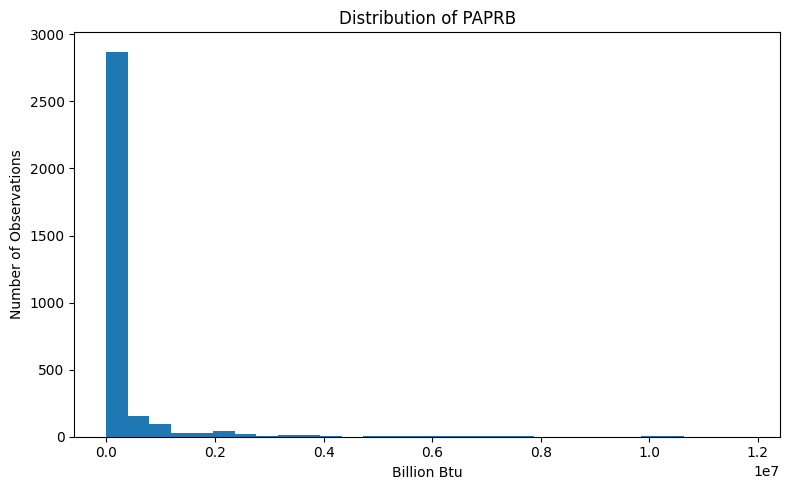

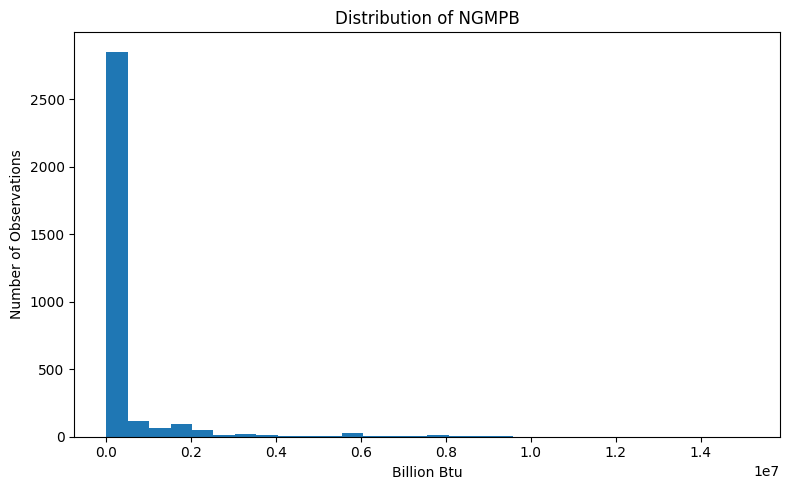

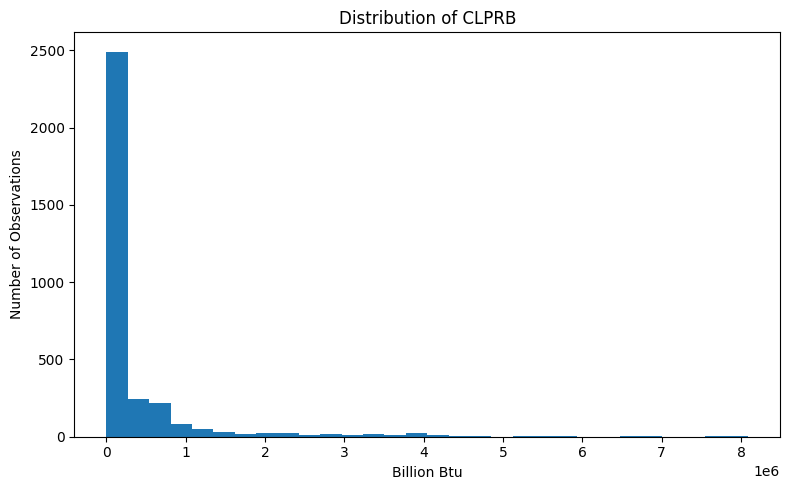

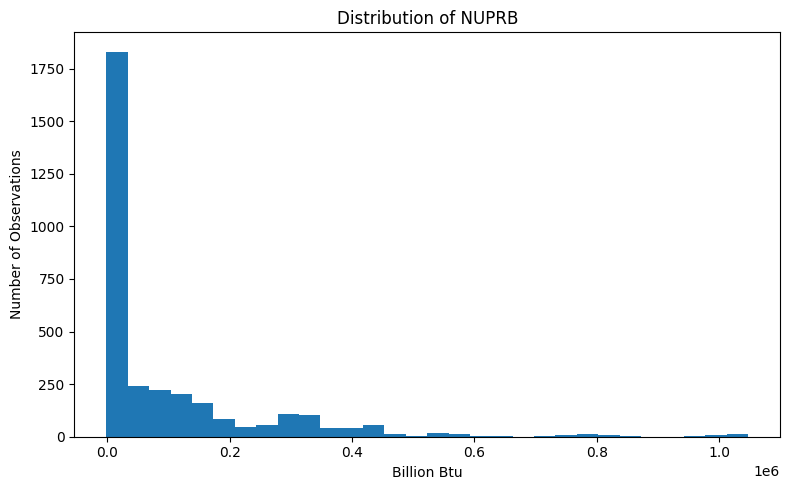

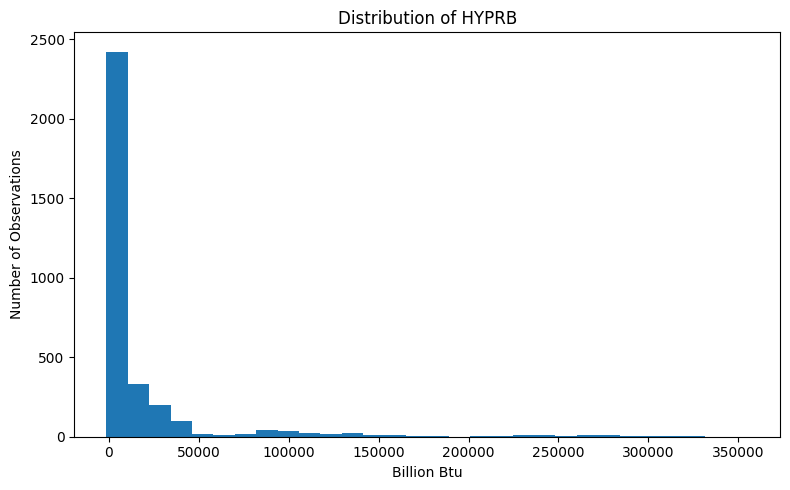

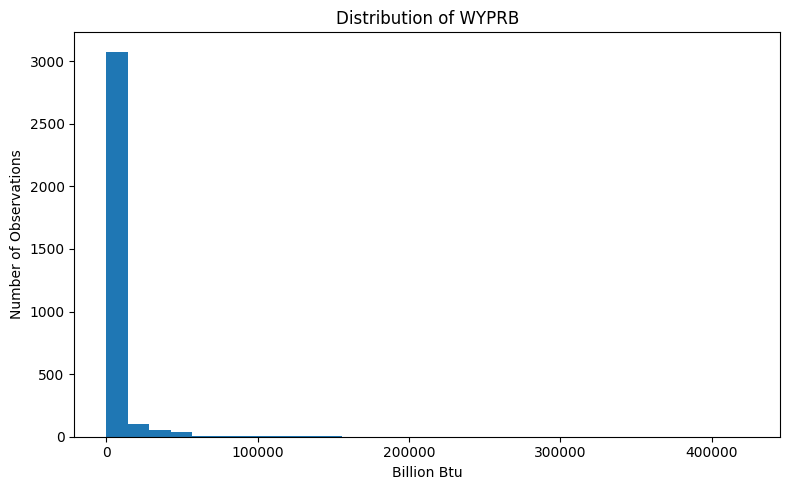

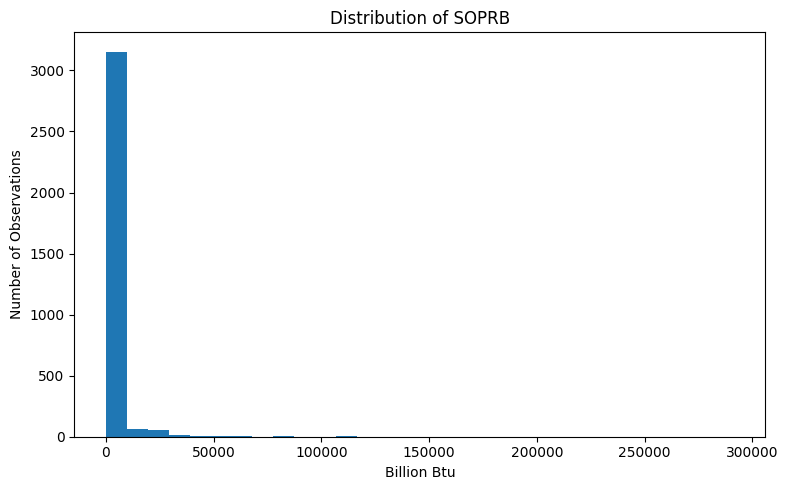

In [13]:

# Histograms for selected production variables
for var in production_vars:
    plt.figure(figsize=(8, 5))

    plt.hist(df[var].dropna(), bins=30)

    plt.title(f'Distribution of {var}')
    plt.xlabel('Billion Btu')
    plt.ylabel('Number of Observations')

    plt.tight_layout()
    plt.show()
    plt.close()

In [14]:
# Aggregate selected production variables across geographic entities by year
yearly_energy = df.groupby('Year')[production_vars].sum()

yearly_energy.head()

,PAPRB,NGMPB,CLPRB,NUPRB,HYPRB,WYPRB,SOPRB
Year,,,,,,,
1960,14699084.0,13836006.0,10590205.0,6027.0,509887.0,0.0,0.0
1961,14883483.0,14304703.0,10239470.0,19678.0,530692.0,0.0,0.0
1962,15076657.0,14857944.0,10670679.0,26394.0,586916.0,0.0,0.0
1963,15406728.0,15690848.0,11605465.0,38147.0,576592.0,0.0,0.0
1964,15518232.0,16482036.0,12273826.0,39820.0,615188.0,0.0,0.0


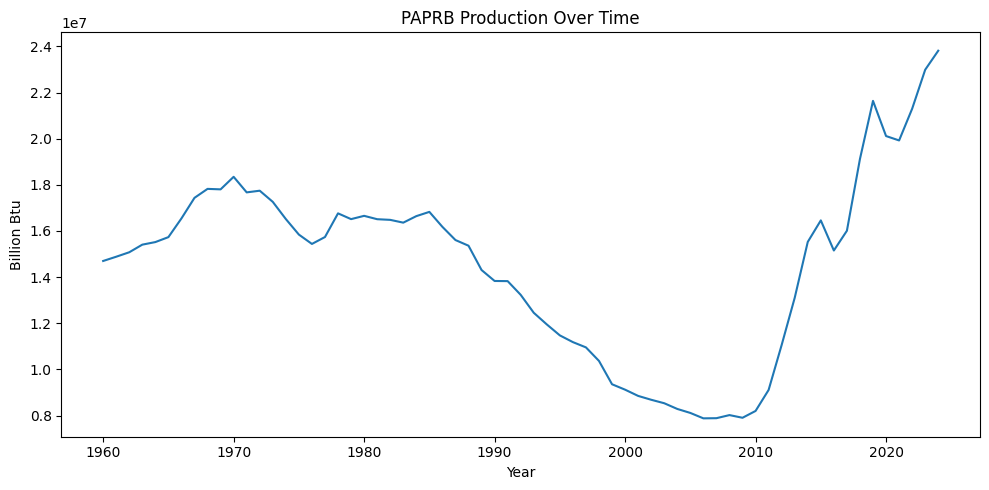

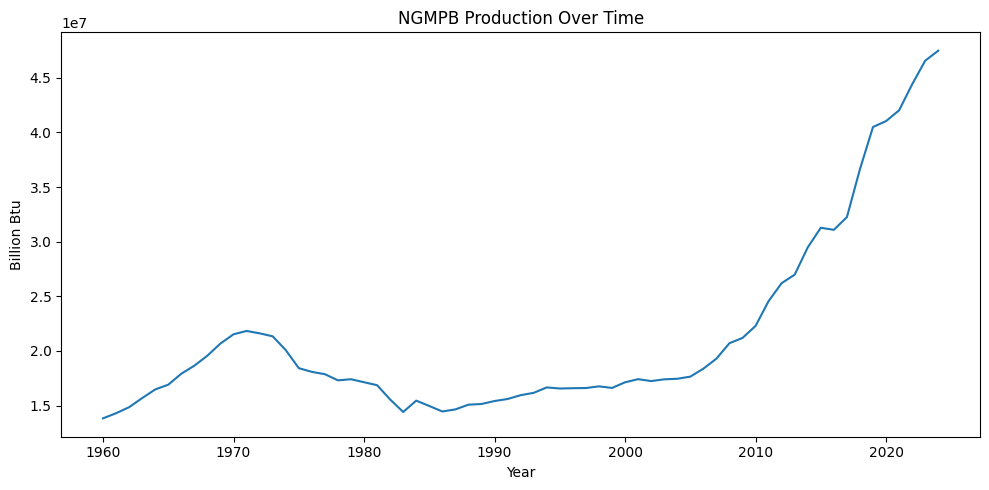

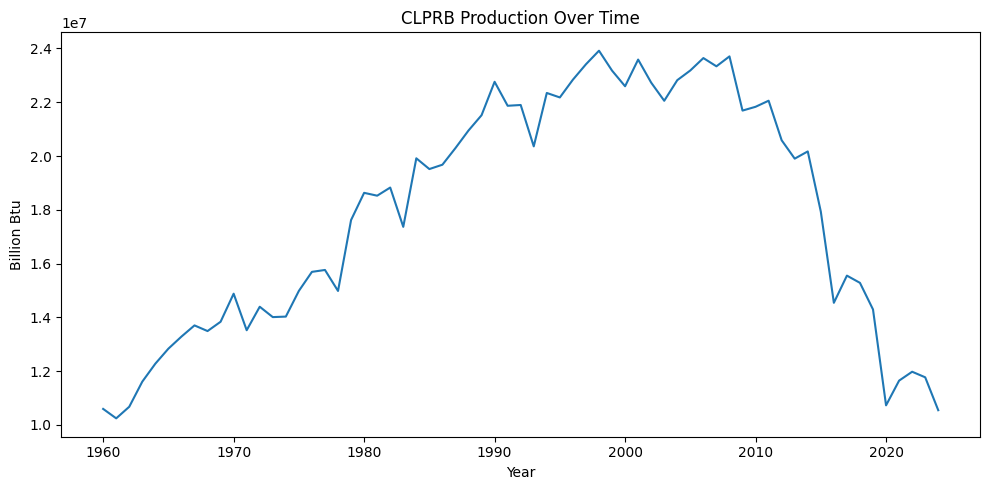

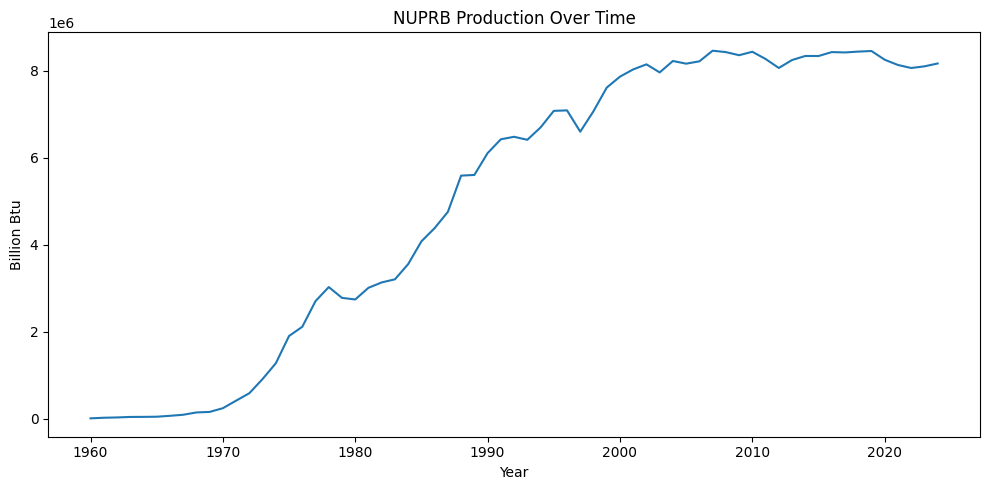

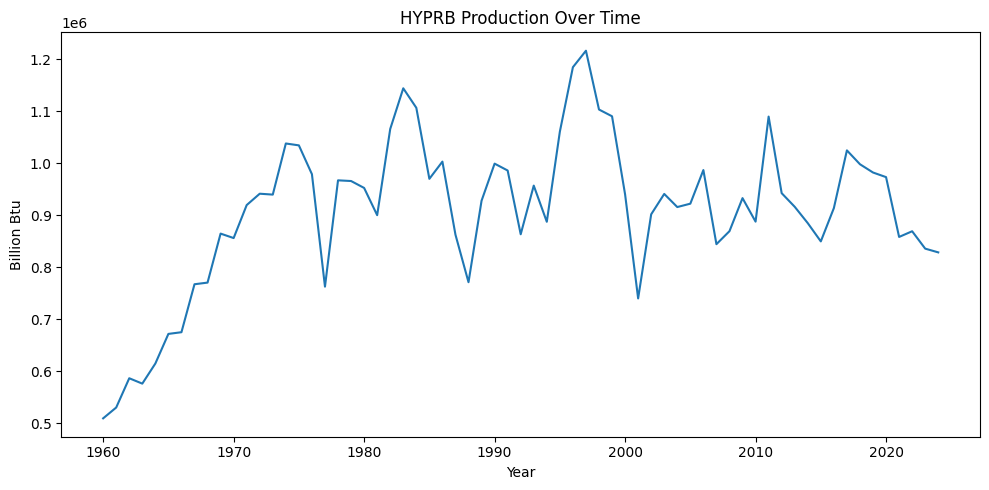

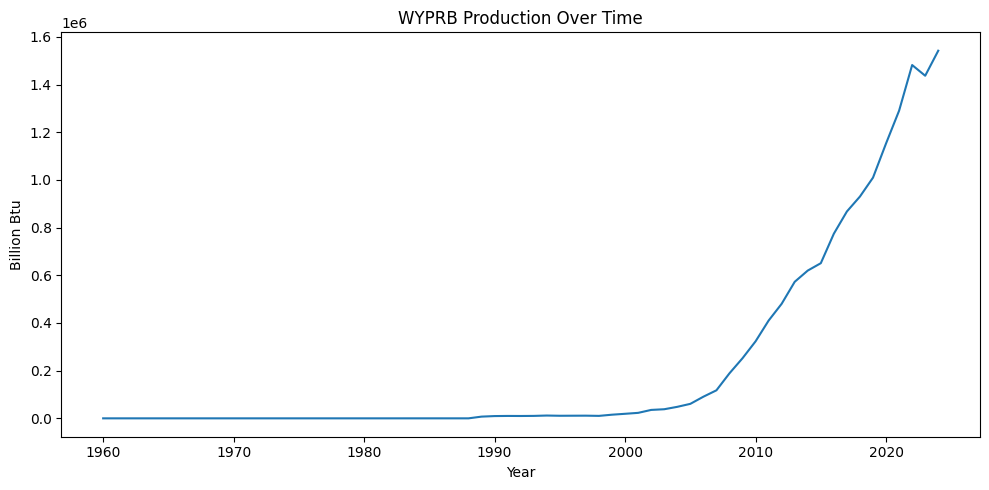

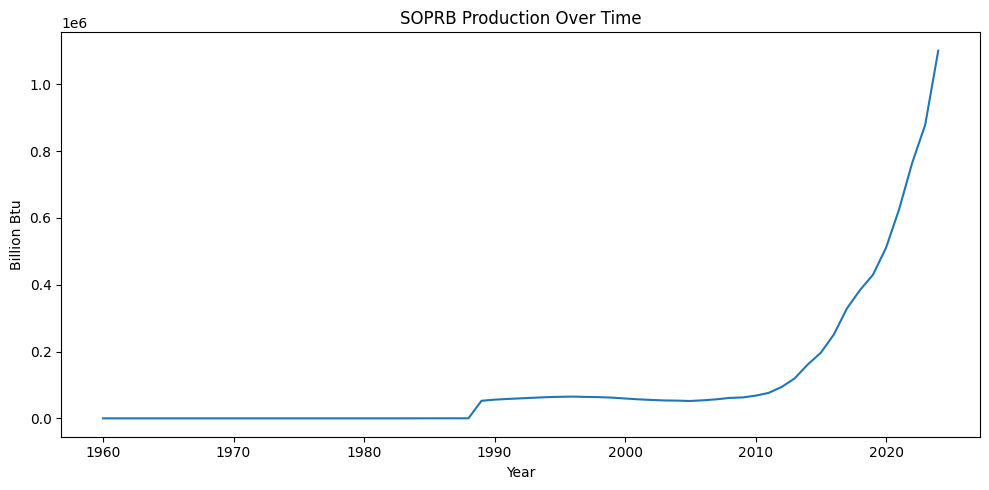

In [15]:
# Plot each selected production variable over time
for var in production_vars:
    plt.figure(figsize=(10, 5))

    plt.plot(yearly_energy.index, yearly_energy[var])

    plt.title(f'{var} Production Over Time')
    plt.xlabel('Year')
    plt.ylabel('Billion Btu')

    plt.tight_layout()
    plt.show()
    plt.close()


In [16]:
# Average crude oil production by state
state_oil = (
    df.groupby('State')['PAPRB']
    .mean()
    .sort_values(ascending=False)
)

state_oil.head(10)

,PAPRB
State,
TX,5.410685e+06
AK,1.744288e+06
CA,1.603386e+06
LA,1.194028e+06
OK,8.138280e+05
NM,7.586904e+05
ND,6.318966e+05
WY,5.849190e+05
KS,3.308538e+05


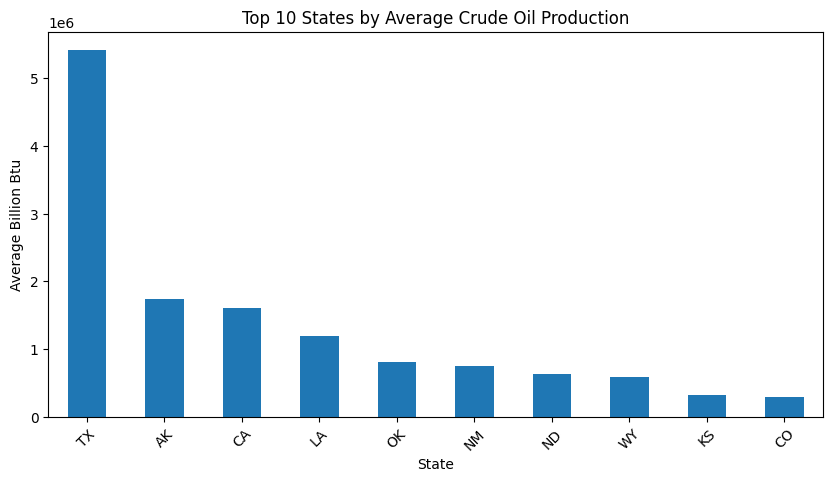

In [17]:
# Plot the 10 states with the highest average crude oil production
state_oil.head(10).plot(
    kind='bar',
    figsize=(10, 5)
)

plt.title('Top 10 States by Average Crude Oil Production')
plt.xlabel('State')
plt.ylabel('Average Billion Btu')
plt.xticks(rotation=45)
plt.show()

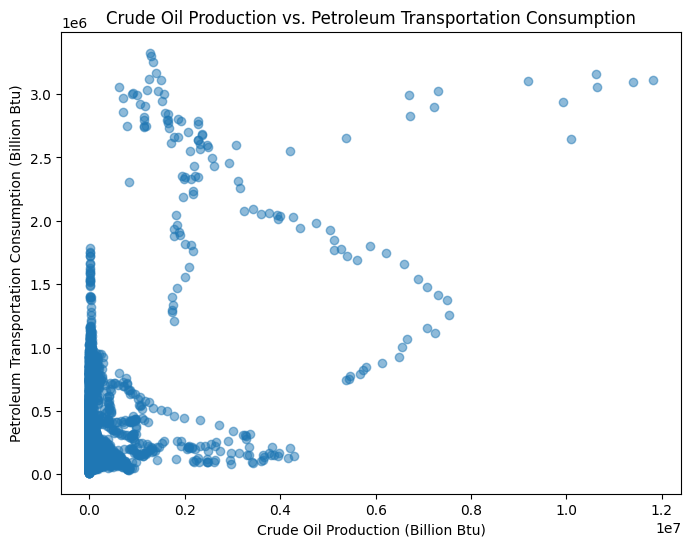

In [18]:
# Compare production and transportation consumption
plt.figure(figsize=(8, 6))

plt.scatter(
    df['PAPRB'],
    df['PAACB'],
    alpha=0.5
)

plt.title('Crude Oil Production vs. Petroleum Transportation Consumption')
plt.xlabel('Crude Oil Production (Billion Btu)')
plt.ylabel('Petroleum Transportation Consumption (Billion Btu)')
plt.show()

In [19]:
correlation_matrix = df[energy_cols].corr()

correlation_matrix.head()

,B1ACB,B1PRB,BDACB,BDCCB,BDEIB,BDFDB,BDRCB,CLACB,CLCCB,CLEIB,...,SORCB,TPOPP,WWCCB,WWEIB,WWICB,WWPRB,WYCCB,WYEGB,WYICB,WYPRB
B1ACB,1.000000,0.456070,0.443755,-0.003563,-0.003133,0.057650,-0.004145,-0.007147,-0.019777,-0.040420,...,0.651872,0.266705,0.229524,0.218932,0.008742,0.080161,0.067472,0.097775,0.080859,0.097825
B1PRB,0.456070,1.000000,0.264494,-0.006229,-0.005380,0.059727,-0.007207,-0.012273,-0.033631,-0.026682,...,0.274509,0.105356,0.048309,0.048386,0.097005,0.086941,0.079788,0.193412,0.037190,0.193401
BDACB,0.443755,0.264494,1.000000,0.078161,-0.006990,0.588749,0.057801,-0.045361,-0.092899,0.150457,...,0.464297,0.450725,0.319243,0.299491,0.139185,0.212437,0.557613,0.653941,0.193072,0.654113
BDCCB,-0.003563,-0.006229,0.078161,1.000000,-0.004943,-0.005758,0.902152,-0.011276,-0.031204,-0.062796,...,0.054303,0.120042,0.250277,0.090611,-0.024078,0.028733,0.037952,0.021906,0.024042,0.021934
BDEIB,-0.003133,-0.005380,-0.006990,-0.004943,1.000000,-0.006231,-0.005719,-0.009738,-0.026906,-0.048811,...,0.039998,-0.037734,0.053001,-0.019387,-0.044462,-0.050788,-0.010020,-0.006197,-0.005200,-0.006204


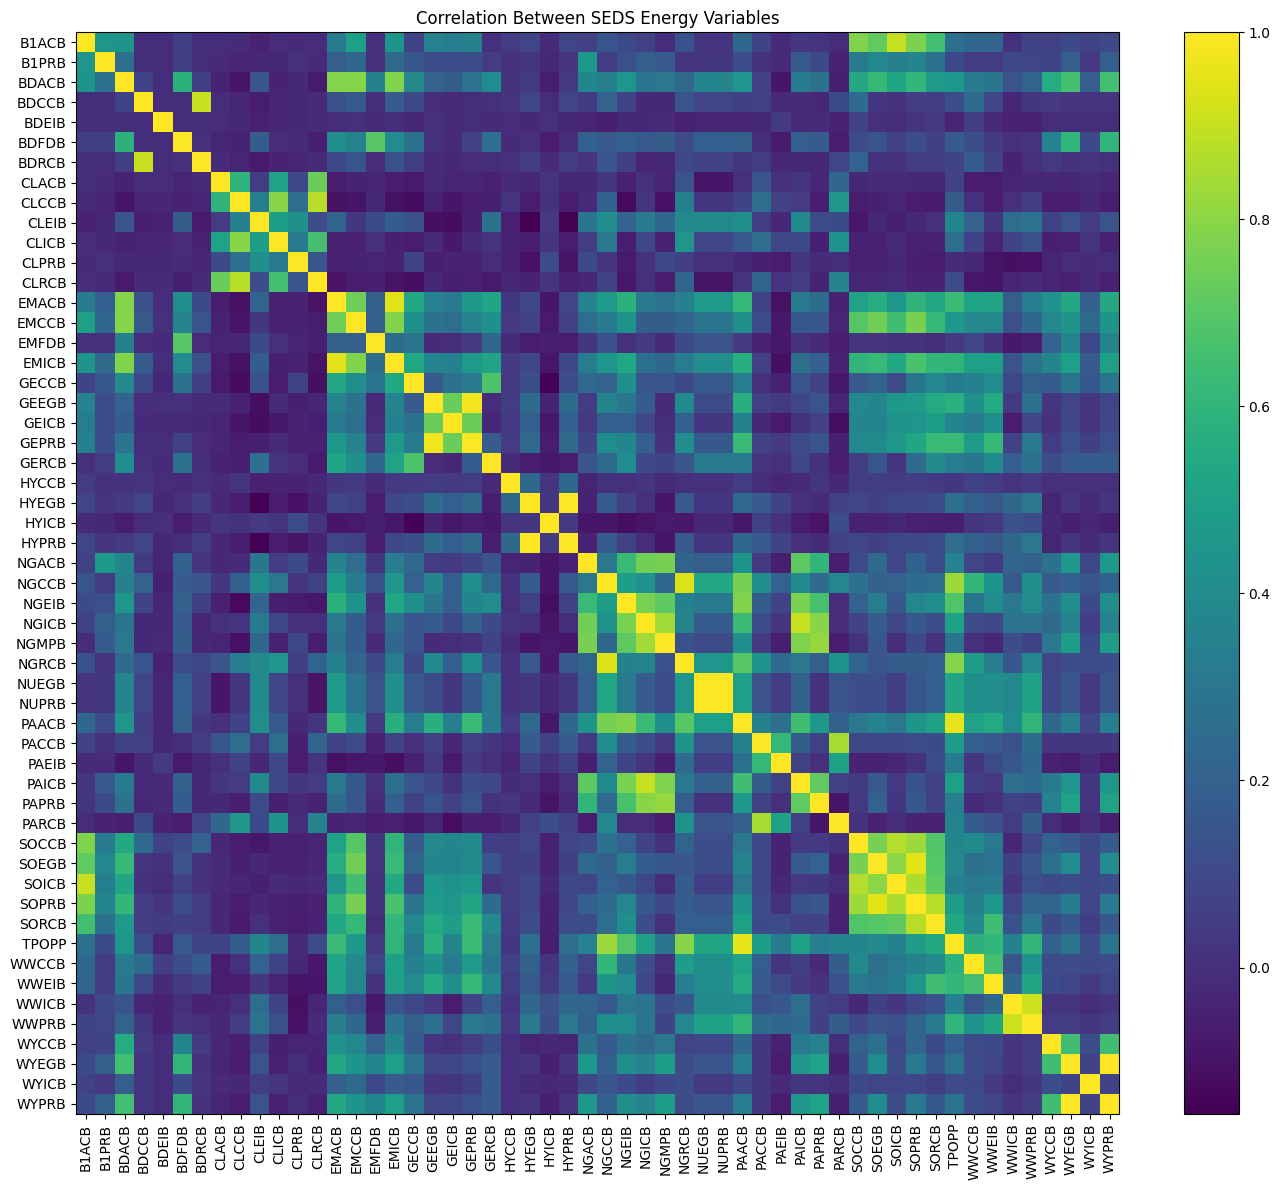

In [20]:
# Visualize the correlation matrix
plt.figure(figsize=(14, 12))

plt.imshow(correlation_matrix, aspect='auto')
plt.colorbar()

plt.xticks(
    range(len(energy_cols)),
    energy_cols,
    rotation=90
)

plt.yticks(
    range(len(energy_cols)),
    energy_cols
)

plt.title('Correlation Between SEDS Energy Variables')
plt.tight_layout()
plt.show()

In [21]:
# Look for the strongest positive and negative pairwise correlations and show them
corr_pairs = (
    correlation_matrix
    .where(np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool))
    .stack()
    .sort_values(ascending=False)
)

print("Strongest positive correlations:")
display(corr_pairs.head(10))

print("\nStrongest negative correlations:")
display(corr_pairs.tail(10))

Strongest positive correlations:


,,0
NUEGB,NUPRB,1.000000
WYEGB,WYPRB,1.000000
HYEGB,HYPRB,0.999895
GEEGB,GEPRB,0.980026
PAACB,TPOPP,0.955870
SOEGB,SOPRB,0.953532
EMACB,EMICB,0.947665
NGCCB,NGRCB,0.937118
WWICB,WWPRB,0.913080
B1ACB,SOICB,0.903273



Strongest negative correlations:


CLRCB  GECCB   -0.107935
CLPRB  WWICB   -0.109079
GEICB  PARCB   -0.114214
HYICB  NGEIB   -0.114247
CLEIB  GEICB   -0.116292
CLCCB  GECCB   -0.116682
       NGEIB   -0.128687
GECCB  HYICB   -0.144157
CLEIB  HYPRB   -0.155693
       HYEGB   -0.156257
dtype: float64

In [22]:
# Ten largest crude oil production observations
df.nlargest(
    10,
    'PAPRB'
)[['State', 'Year', 'PAPRB']]

,State,Year,PAPRB
2859,TX,2024,11816810.0
2858,TX,2023,11388741.0
2857,TX,2022,10632365.0
2854,TX,2019,10626707.0
2855,TX,2020,10102510.0
2856,TX,2021,9937414.0
2853,TX,2018,9202197.0
2807,TX,1972,7539574.0
2808,TX,1973,7499885.0
2809,TX,1974,7312336.0


In [23]:
# Ten largest natural gas production observations
df.nlargest(
    10,
    'NGMPB'
)[['State', 'Year', 'NGMPB']]

,State,Year,NGMPB
2859,TX,2024,15116516.0
2858,TX,2023,14189114.0
2857,TX,2022,13175140.0
2856,TX,2021,12172271.0
2855,TX,2020,11951894.0
2854,TX,2019,11323138.0
2853,TX,2018,9776991.0
2807,TX,1972,9550844.0
2806,TX,1971,9438928.0
2850,TX,2015,9392314.0


In [24]:
# Average production profile for each state
state_energy = df.groupby('State')[production_vars].mean()

state_energy.head()

,PAPRB,NGMPB,CLPRB,NUPRB,HYPRB,WYPRB,SOPRB
State,,,,,,,
AK,1.744288e+06,327709.230769,18225.000000,0.000000,3303.923077,93.076923,5.738462
AL,6.839443e+04,165829.753846,479556.076923,235248.953846,31412.184615,0.000000,330.907692
AR,7.479312e+04,305259.138462,3295.615385,96619.415385,9608.723077,0.000000,605.400000
AZ,1.899569e+03,538.446154,159342.107692,173620.846154,24795.400000,661.430769,7063.046154
CA,1.603386e+06,417695.169231,79.938462,192623.569231,108805.123077,13965.707692,37181.784615
